# 06 — Backtesting de la política de abastecimiento

**Tostao | Pronóstico diario agregado a 7 días | Política Q85 / Q90 / Q95**

## Objetivo
Evaluar cómo se habría comportado una política semanal de inventario frente a semanas históricas no utilizadas para entrenar el pronóstico.

Este notebook amplía la validación temporal del Notebook 03: en lugar de depender únicamente de tres bloques de prueba, utiliza ventanas móviles de siete días con entrenamiento expansivo.

### Qué se evalúa
- Pronóstico ETS por SKU–Tienda para cada semana histórica.
- Calibración de incertidumbre usando exclusivamente errores de semanas anteriores.
- Inventario objetivo Q85, Q90 y Q95.
- Tope de cobertura de 8 días y sensibilidad de 7, 8 y 9 días.
- Faltantes y excedentes simulados.
- Unidades sugeridas y costo proxy de faltante/exceso.
- Sensibilidad a distintos niveles hipotéticos de stock inicial.

### Alcance y supuestos importantes
No existe inventario histórico por fecha ni información de lead time o pedidos en tránsito. Por eso, esto es una **simulación contrafactual de política semanal**, no una reconstrucción exacta de lo que ocurrió en las tiendas.

Se asume que el pedido llega al inicio de la semana. El stock inicial se evalúa en escenarios equivalentes al 0%, 50% y 100% del pronóstico puntual semanal. Las ventas observadas se utilizan como proxy de demanda, aunque podrían estar censuradas por quiebres de stock.


## 1. Carga de datos y parámetros

Requiere:
- `ventas_historicas.csv`
- `catalogo_productos.csv`
- `maestro_tiendas.csv`

El horizonte es de siete días. Se requieren al menos 28 días de entrenamiento para ajustar ETS con patrón semanal. La validación usa todos los bloques semanales completos disponibles después de ese período.


In [ ]:
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from sklearn.metrics import mean_absolute_error, mean_squared_error

SEED = 42
rng = np.random.default_rng(SEED)
HORIZON = 7
MIN_TRAIN_DAYS = 28
MIN_PRIOR_RESIDUALS = 20
SERVICE_LEVELS = [0.85, 0.90, 0.95]
COVERAGE_DAYS_BASE = 8
OPENING_STOCK_SCENARIOS = [0.0, 0.5, 1.0]

try:
    from google.colab import files
    required = ["ventas_historicas.csv", "catalogo_productos.csv", "maestro_tiendas.csv"]
    missing = [f for f in required if not Path("/content", f).exists() and not Path(f).exists()]
    if missing:
        print("Carga los archivos requeridos:", missing)
        files.upload()
except Exception:
    pass

def locate(name):
    for p in [Path("/content") / name, Path("/mnt/data") / name, Path(name)]:
        if p.exists():
            return p
    raise FileNotFoundError(f"No se encontró {name}. Carga el archivo antes de continuar.")

sales = pd.read_csv(locate("ventas_historicas.csv"))
products = pd.read_csv(locate("catalogo_productos.csv"))
stores = pd.read_csv(locate("maestro_tiendas.csv"))

print("Ventas:", sales.shape)
print("Productos:", products.shape)
print("Tiendas:", stores.shape)


Ventas: (14560, 4)
Productos: (8, 6)
Tiendas: (20, 3)


## 2. Calidad, granularidad y panel diario

Se valida la estructura de columnas, se agregan posibles duplicados de fecha–tienda–producto y se construye un panel diario completo por SKU–Tienda. Los días sin registro se completan con cero, siguiendo el supuesto utilizado en los notebooks anteriores.

Un cero de venta no necesariamente equivale a demanda cero: podría existir quiebre o falta de captura. Esta limitación se conserva en la interpretación.


In [ ]:
required_sales = {"fecha", "id_tienda", "id_producto", "unidades_vendidas"}
required_products = {"id_producto", "costo_unitario", "precio_venta", "costo_almacenamiento_semanal"}
required_stores = {"id_tienda", "ciudad", "tamaño_m2"}

for label, df, required_cols in [
    ("ventas", sales, required_sales),
    ("catálogo", products, required_products),
    ("tiendas", stores, required_stores)
]:
    missing = required_cols - set(df.columns)
    if missing:
        raise ValueError(f"Faltan columnas en {label}: {missing}")

sales["fecha"] = pd.to_datetime(sales["fecha"], errors="coerce")
sales["unidades_vendidas"] = pd.to_numeric(sales["unidades_vendidas"], errors="coerce")
sales = sales.dropna(subset=["fecha", "id_tienda", "id_producto", "unidades_vendidas"])
if (sales["unidades_vendidas"] < 0).any():
    raise ValueError("Se encontraron ventas negativas; revisar devoluciones/ajustes antes de continuar.")

sales["id_tienda"] = sales["id_tienda"].astype(str).str.strip()
sales["id_producto"] = sales["id_producto"].astype(str).str.strip()
products["id_producto"] = products["id_producto"].astype(str).str.strip()
stores["id_tienda"] = stores["id_tienda"].astype(str).str.strip()

sales = (sales.groupby(["fecha", "id_tienda", "id_producto"], as_index=False)
               ["unidades_vendidas"].sum()
               .rename(columns={"unidades_vendidas": "y"}))

date_min, date_max = sales["fecha"].min(), sales["fecha"].max()
dates = pd.date_range(date_min, date_max, freq="D")
keys = sales[["id_tienda", "id_producto"]].drop_duplicates()

panel = (keys.assign(_k=1)
         .merge(pd.DataFrame({"fecha": dates, "_k": 1}), on="_k")
         .drop(columns="_k")
         .merge(sales, on=["fecha", "id_tienda", "id_producto"], how="left"))
panel["y"] = panel["y"].fillna(0).astype(float)
panel = panel.sort_values(["id_tienda", "id_producto", "fecha"]).reset_index(drop=True)

print("Periodo:", date_min.date(), "a", date_max.date())
print("Días:", len(dates), "| Combinaciones SKU–Tienda:", len(keys))
print("Filas panel:", len(panel))


Periodo: 2024-01-01 a 2024-03-31
Días: 91 | Combinaciones SKU–Tienda: 160
Filas panel: 14560


## 3. Ventanas temporales expansivas

Cada fold utiliza únicamente fechas anteriores al inicio del bloque de prueba para entrenar. Se predicen los siete días siguientes y luego se comparan con las ventas observadas.

Con 91 días y 28 días mínimos de entrenamiento se esperan nueve bloques semanales completos. El número efectivo se calcula automáticamente.


In [ ]:
unique_dates = pd.DatetimeIndex(sorted(panel["fecha"].unique()))
folds = []
start_idx = MIN_TRAIN_DAYS
fold_id = 1

while start_idx + HORIZON <= len(unique_dates):
    test_dates = unique_dates[start_idx:start_idx + HORIZON]
    folds.append({
        "fold": fold_id,
        "train_end": test_dates[0] - pd.Timedelta(days=1),
        "test_start": test_dates[0],
        "test_end": test_dates[-1]
    })
    fold_id += 1
    start_idx += HORIZON

folds_df = pd.DataFrame(folds)
if len(folds_df) < 3:
    raise ValueError("Se necesitan al menos tres folds semanales completos para evaluar la política.")

display(folds_df)
print("Folds disponibles:", len(folds_df))


,fold,train_end,test_start,test_end
0,1,2024-01-28,2024-01-29,2024-02-04
1,2,2024-02-04,2024-02-05,2024-02-11
2,3,2024-02-11,2024-02-12,2024-02-18
3,4,2024-02-18,2024-02-19,2024-02-25
4,5,2024-02-25,2024-02-26,2024-03-03
5,6,2024-03-03,2024-03-04,2024-03-10
6,7,2024-03-10,2024-03-11,2024-03-17
7,8,2024-03-17,2024-03-18,2024-03-24
8,9,2024-03-24,2024-03-25,2024-03-31


Folds disponibles: 9


## 4. Función ETS y pronóstico por fold

Se replica el enfoque del Notebook 03: ETS aditivo con tendencia amortiguada y estacionalidad semanal. Si el ajuste falla, se utiliza Seasonal Naive 7 como respaldo y se registra el fallback para transparencia.


In [ ]:
def forecast_ets_or_fallback(y, steps=7):
    y = pd.Series(y, dtype=float).clip(lower=0).reset_index(drop=True)
    try:
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter("always")
            fit = ExponentialSmoothing(
                y, trend="add", damped_trend=True,
                seasonal="add", seasonal_periods=7,
                initialization_method="estimated"
            ).fit(
                optimized=True, use_brute=False,
                minimize_kwargs={"options": {"maxiter": 200}}
            )
        converged = getattr(fit, "mle_retvals", {}).get("success", True)
        if not converged:
            raise RuntimeError("ETS no convergió dentro del máximo de iteraciones.")
        pred = np.asarray(fit.forecast(steps), dtype=float)
        return np.clip(pred, 0, None), "ETS_Aditivo_7"
    except Exception:
        pred = np.resize(y.iloc[-7:].to_numpy(), steps)
        return np.clip(pred, 0, None), "Seasonal_Naive_7_fallback"

forecast_rows = []
for fold in folds:
    train = panel[panel["fecha"] <= fold["train_end"]]
    test = panel[
        (panel["fecha"] >= fold["test_start"]) &
        (panel["fecha"] <= fold["test_end"])
    ]

    for (store, product), g in train.groupby(["id_tienda", "id_producto"]):
        g = g.sort_values("fecha")
        if len(g) < MIN_TRAIN_DAYS:
            continue

        pred, model_used = forecast_ets_or_fallback(g["y"], HORIZON)
        actual = test[
            (test["id_tienda"] == store) &
            (test["id_producto"] == product)
        ].sort_values("fecha")

        if len(actual) != HORIZON:
            continue

        actual_values = actual["y"].to_numpy(dtype=float)
        weekly_pred = float(np.sum(pred))
        weekly_actual = float(np.sum(actual_values))

        forecast_rows.append({
            "fold": fold["fold"],
            "train_end": fold["train_end"],
            "test_start": fold["test_start"],
            "test_end": fold["test_end"],
            "id_tienda": store,
            "id_producto": product,
            "demanda_predicha_7d": weekly_pred,
            "demanda_real_7d": weekly_actual,
            "modelo_utilizado": model_used
        })

fold_forecasts = pd.DataFrame(forecast_rows)
if fold_forecasts.empty:
    raise ValueError("No se generaron pronósticos. Revisar fechas y granularidad.")

fold_forecasts["error"] = (
    fold_forecasts["demanda_real_7d"] - fold_forecasts["demanda_predicha_7d"]
)
fold_forecasts["error_relativo"] = (
    fold_forecasts["error"] /
    fold_forecasts["demanda_predicha_7d"].clip(lower=1)
)

print("Pronósticos SKU–Tienda–Fold:", len(fold_forecasts))
print("Fallbacks ETS:", int((fold_forecasts["modelo_utilizado"] != "ETS_Aditivo_7").sum()))
display(fold_forecasts.head())


Pronósticos SKU–Tienda–Fold: 1440
Fallbacks ETS: 0


,fold,train_end,test_start,test_end,id_tienda,id_producto,demanda_predicha_7d,demanda_real_7d,modelo_utilizado,error,error_relativo
0,1,2024-01-28,2024-01-29,2024-02-04,STORE_01,PROD_001,57.718146,54.0,ETS_Aditivo_7,-3.718146,-0.064419
1,1,2024-01-28,2024-01-29,2024-02-04,STORE_01,PROD_002,49.302430,73.0,ETS_Aditivo_7,23.697570,0.480657
2,1,2024-01-28,2024-01-29,2024-02-04,STORE_01,PROD_003,66.142266,55.0,ETS_Aditivo_7,-11.142266,-0.168459
3,1,2024-01-28,2024-01-29,2024-02-04,STORE_01,PROD_004,35.332530,39.0,ETS_Aditivo_7,3.667470,0.103799
4,1,2024-01-28,2024-01-29,2024-02-04,STORE_01,PROD_005,81.251134,108.0,ETS_Aditivo_7,26.748866,0.329212


## 5. Métricas de pronóstico fuera de muestra

Las métricas se calculan sobre la demanda semanal agregada de cada combinación y fold. WAPE es la métrica principal de lectura agregada. El sesgo positivo indica sobrepronóstico; negativo, subpronóstico, según la definición de esta tabla.


In [ ]:
def forecast_metrics(df):
    y = df["demanda_real_7d"].to_numpy(dtype=float)
    p = df["demanda_predicha_7d"].to_numpy(dtype=float)
    denom = np.abs(y).sum()
    return pd.Series({
        "MAE_semanal": mean_absolute_error(y, p),
        "RMSE_semanal": mean_squared_error(y, p) ** 0.5,
        "WAPE": np.abs(y-p).sum()/denom if denom else np.nan,
        "Sesgo_pred_menos_real": (p-y).sum()/denom if denom else np.nan,
        "N": len(df)
    })

forecast_metrics_overall = forecast_metrics(fold_forecasts).to_frame("Valor")
fold_metric_rows = []
for fold_id, fold_df in fold_forecasts.groupby("fold"):
    row = {"fold": fold_id}
    row.update(forecast_metrics(fold_df).to_dict())
    fold_metric_rows.append(row)
forecast_metrics_by_fold = pd.DataFrame(fold_metric_rows)
display(forecast_metrics_overall)
display(forecast_metrics_by_fold)


,Valor
MAE_semanal,11.162724
RMSE_semanal,14.606407
WAPE,0.120257
Sesgo_pred_menos_real,0.004518
N,1440.000000


,fold,MAE_semanal,RMSE_semanal,WAPE,Sesgo_pred_menos_real,N
0,1,11.832306,15.841655,0.128533,-0.001375,160.0
1,2,12.421558,15.640566,0.134106,-0.003973,160.0
2,3,11.437366,14.913946,0.123148,-0.000492,160.0
3,4,11.455301,14.827798,0.122903,-0.000428,160.0
4,5,10.757881,14.517664,0.115824,0.013340,160.0
5,6,10.249396,13.075157,0.111459,0.016799,160.0
6,7,11.027591,14.184037,0.118401,0.003019,160.0
7,8,10.000843,13.196972,0.107104,0.003040,160.0
8,9,11.282280,15.006001,0.120925,0.010778,160.0


## 6. Simulación de política con calibración sin fuga de información

Para cada fold de evaluación:
1. Se utilizan únicamente los errores relativos de folds anteriores.
2. Se agrupan los errores por producto, compartiendo información entre tiendas del mismo producto.
3. Se generan escenarios de demanda semanal alrededor del pronóstico del fold actual.
4. Se calculan Q85, Q90 y Q95.
5. Se limita el inventario objetivo a la cobertura máxima de ocho días.

**Warm-up:** los dos primeros folds se usan para acumular errores históricos y no se puntúan como simulación de política. La evaluación de política comienza cuando existen al menos 20 residuos previos por producto; si no, se usa el pool global histórico disponible. Nunca se utilizan los errores del fold que se está evaluando para calibrar su propio objetivo.


In [ ]:
policy_rows = []
MIN_POOL = 20
N_SIM = 5000
rng_policy = np.random.default_rng(SEED)

all_products = sorted(fold_forecasts["id_producto"].unique())
evaluated_folds = sorted(fold_forecasts["fold"].unique())

for fold_id in evaluated_folds:
    prior = fold_forecasts[fold_forecasts["fold"] < fold_id].copy()
    current = fold_forecasts[fold_forecasts["fold"] == fold_id].copy()

    # No usar el fold actual para construir la distribución de errores.
    global_pool = prior["error_relativo"].replace([np.inf, -np.inf], np.nan).dropna().to_numpy()
    if len(global_pool) < MIN_POOL:
        print(f"Fold {fold_id}: warm-up, residuos previos insuficientes ({len(global_pool)}).")
        continue

    product_pools = {
        prod: g["error_relativo"].replace([np.inf, -np.inf], np.nan).dropna().to_numpy()
        for prod, g in prior.groupby("id_producto")
    }

    for _, row in current.iterrows():
        prod = row["id_producto"]
        pool = product_pools.get(prod, np.array([]))
        pool_source = "producto"
        if len(pool) < MIN_POOL:
            pool = global_pool
            pool_source = "global"

        if len(pool) < MIN_POOL:
            continue

        point = max(0.0, float(row["demanda_predicha_7d"]))
        sampled = rng_policy.choice(pool, size=N_SIM, replace=True)
        demand_scenarios = np.maximum(0, point * (1 + sampled))

        q = {alpha: float(np.quantile(demand_scenarios, alpha))
             for alpha in SERVICE_LEVELS}
        cap_8d = int(np.ceil(point * 8 / 7))

        policy_rows.append({
            **row.to_dict(),
            "pool_residuos": pool_source,
            "n_residuos_calibracion": len(pool),
            "q85_sin_tope": q[0.85],
            "q90_sin_tope": q[0.90],
            "q95_sin_tope": q[0.95],
            "tope_8_dias": cap_8d,
            "q85_objetivo": min(int(np.ceil(q[0.85])), cap_8d),
            "q90_objetivo": min(int(np.ceil(q[0.90])), cap_8d),
            "q95_objetivo": min(int(np.ceil(q[0.95])), cap_8d)
        })

policy_targets = pd.DataFrame(policy_rows)
if policy_targets.empty:
    raise ValueError("No se generaron folds evaluables para la política. Revisar historial.")

print("Folds evaluados para política:", sorted(policy_targets["fold"].unique()))
print("Filas SKU–Tienda–Fold:", len(policy_targets))
display(policy_targets.head())


Fold 1: warm-up, residuos previos insuficientes (0).
Folds evaluados para política: [np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9)]
Filas SKU–Tienda–Fold: 1280


,fold,train_end,test_start,test_end,id_tienda,id_producto,demanda_predicha_7d,demanda_real_7d,modelo_utilizado,error,error_relativo,pool_residuos,n_residuos_calibracion,q85_sin_tope,q90_sin_tope,q95_sin_tope,tope_8_dias,q85_objetivo,q90_objetivo,q95_objetivo
0,2,2024-02-04,2024-02-05,2024-02-11,STORE_01,PROD_001,58.986531,53.0,ETS_Aditivo_7,-5.986531,-0.101490,producto,20,70.638317,72.543887,84.453983,68,68,68,68
1,2,2024-02-04,2024-02-05,2024-02-11,STORE_01,PROD_002,64.779069,67.0,ETS_Aditivo_7,2.220931,0.034285,producto,20,84.251782,91.849109,91.849109,75,75,75,75
2,2,2024-02-04,2024-02-05,2024-02-11,STORE_01,PROD_003,63.457295,46.0,ETS_Aditivo_7,-17.457295,-0.275103,producto,20,73.588153,78.741106,79.675082,73,73,73,73
3,2,2024-02-04,2024-02-05,2024-02-11,STORE_01,PROD_004,36.418012,54.0,ETS_Aditivo_7,17.581988,0.482783,producto,20,43.832337,47.290594,57.544293,42,42,42,42
4,2,2024-02-04,2024-02-05,2024-02-11,STORE_01,PROD_005,94.840651,79.0,ETS_Aditivo_7,-15.840651,-0.167024,producto,20,111.885325,123.329531,126.063352,109,109,109,109


## 7. Costos proxy y escenarios de stock inicial

No hay inventario histórico por semana. Para no inventarlo, se prueban tres escenarios de stock inicial:

- 0% del pronóstico semanal.
- 50% del pronóstico semanal.
- 100% del pronóstico semanal.

Se supone que el pedido llega antes de iniciar la semana. El inventario disponible simulado es el mayor entre stock inicial y objetivo de inventario, porque el pedido repone hasta el objetivo.

**Costo de faltante proxy:** margen unitario (precio menos costo) multiplicado por unidades no atendidas. Supone que la venta perdida no se recupera ni sustituye.

**Costo de excedente proxy:** costo de almacenamiento semanal multiplicado por unidades sobrantes. No incluye capital, merma, vencimiento, markdown ni capacidad. Por tanto, el costo total es ilustrativo, no costo financiero completo.


In [ ]:
products["id_producto"] = products["id_producto"].astype(str).str.strip()
for c in ["costo_unitario", "precio_venta", "costo_almacenamiento_semanal"]:
    products[c] = pd.to_numeric(products[c], errors="coerce")

if products[["costo_unitario", "precio_venta", "costo_almacenamiento_semanal"]].isna().any().any():
    raise ValueError("El catálogo tiene costos o precios faltantes/no numéricos.")

products["margen_unitario_proxy"] = (
    products["precio_venta"] - products["costo_unitario"]
).clip(lower=0)

sim_rows = []
for _, row in policy_targets.iterrows():
    prod = str(row["id_producto"])
    pinfo = products.loc[products["id_producto"] == prod]
    if pinfo.empty:
        raise ValueError(f"Producto {prod} no encontrado en catálogo.")
    pinfo = pinfo.iloc[0]

    for alpha in SERVICE_LEVELS:
        policy = f"Q{int(alpha*100)}"
        target = int(row[f"q{int(alpha*100)}_objetivo"])

        for opening_pct in OPENING_STOCK_SCENARIOS:
            opening_stock = int(np.ceil(
                max(0, row["demanda_predicha_7d"]) * opening_pct
            ))
            order_qty = max(0, target - opening_stock)
            available = opening_stock + order_qty
            actual = max(0.0, float(row["demanda_real_7d"]))
            shortage = max(0.0, actual - available)
            excess = max(0.0, available - actual)

            underage_cost = shortage * float(pinfo["margen_unitario_proxy"])
            overage_cost = excess * float(pinfo["costo_almacenamiento_semanal"])

            sim_rows.append({
                "fold": int(row["fold"]),
                "id_tienda": row["id_tienda"],
                "id_producto": prod,
                "politica": policy,
                "stock_inicial_pct_forecast": opening_pct,
                "demanda_predicha_7d": float(row["demanda_predicha_7d"]),
                "demanda_real_7d": actual,
                "stock_inicial_simulado": opening_stock,
                "inventario_objetivo": target,
                "pedido_sugerido_simulado": order_qty,
                "disponible_simulado": available,
                "faltante_unidades": shortage,
                "excedente_unidades": excess,
                "fill_rate": 1 - shortage/actual if actual > 0 else 1.0,
                "costo_faltante_proxy": underage_cost,
                "costo_excedente_proxy": overage_cost,
                "costo_total_proxy": underage_cost + overage_cost
            })

policy_simulation = pd.DataFrame(sim_rows)
display(policy_simulation.head())


,fold,id_tienda,id_producto,politica,stock_inicial_pct_forecast,demanda_predicha_7d,demanda_real_7d,stock_inicial_simulado,inventario_objetivo,pedido_sugerido_simulado,disponible_simulado,faltante_unidades,excedente_unidades,fill_rate,costo_faltante_proxy,costo_excedente_proxy,costo_total_proxy
0,2,STORE_01,PROD_001,Q85,0.0,58.986531,53.0,0,68,68,68,0.0,15.0,1.0,0.0,150.0,150.0
1,2,STORE_01,PROD_001,Q85,0.5,58.986531,53.0,30,68,38,68,0.0,15.0,1.0,0.0,150.0,150.0
2,2,STORE_01,PROD_001,Q85,1.0,58.986531,53.0,59,68,9,68,0.0,15.0,1.0,0.0,150.0,150.0
3,2,STORE_01,PROD_001,Q90,0.0,58.986531,53.0,0,68,68,68,0.0,15.0,1.0,0.0,150.0,150.0
4,2,STORE_01,PROD_001,Q90,0.5,58.986531,53.0,30,68,38,68,0.0,15.0,1.0,0.0,150.0,150.0


## 8. Resultados comparativos Q85 / Q90 / Q95

La tabla resume los resultados para cada escenario de stock inicial. El fill rate se calcula de forma agregada como 1 menos faltantes totales dividido por demanda real total. Se recomienda leer primero el escenario de 50% del pronóstico como caso intermedio, pero no debe confundirse con un dato observado. Como la política repone hasta el objetivo al inicio de la semana, los escenarios de stock inicial alteran el pedido, pero no la disponibilidad final cuando el stock inicial es inferior al objetivo.


In [ ]:
policy_results = (
    policy_simulation.groupby(["stock_inicial_pct_forecast", "politica"], as_index=False)
    .agg(
        observaciones_sku_tienda_fold=("fold", "count"),
        demanda_real_total=("demanda_real_7d", "sum"),
        pedido_total=("pedido_sugerido_simulado", "sum"),
        faltantes_unidades=("faltante_unidades", "sum"),
        excedentes_unidades=("excedente_unidades", "sum"),
        costo_faltante_proxy=("costo_faltante_proxy", "sum"),
        costo_excedente_proxy=("costo_excedente_proxy", "sum"),
        costo_total_proxy=("costo_total_proxy", "sum")
    )
)
policy_results["fill_rate_global"] = np.where(
    policy_results["demanda_real_total"] > 0,
    1 - policy_results["faltantes_unidades"] / policy_results["demanda_real_total"],
    1.0
)
display(policy_results)


,stock_inicial_pct_forecast,politica,observaciones_sku_tienda_fold,demanda_real_total,pedido_total,faltantes_unidades,excedentes_unidades,costo_faltante_proxy,costo_excedente_proxy,costo_total_proxy,fill_rate_global
0,0.0,Q85,1280,118937.0,137018,1542.0,19623.0,3543400.0,499085.0,4042485.0,0.987035
1,0.0,Q90,1280,118937.0,137284,1498.0,19845.0,3438800.0,507435.0,3946235.0,0.987405
2,0.0,Q95,1280,118937.0,137293,1495.0,19851.0,3429800.0,507735.0,3937535.0,0.987430
3,0.5,Q85,1280,118937.0,76591,1542.0,19623.0,3543400.0,499085.0,4042485.0,0.987035
4,0.5,Q90,1280,118937.0,76857,1498.0,19845.0,3438800.0,507435.0,3946235.0,0.987405
5,0.5,Q95,1280,118937.0,76866,1495.0,19851.0,3429800.0,507735.0,3937535.0,0.987430
6,1.0,Q85,1280,118937.0,16807,1542.0,19623.0,3543400.0,499085.0,4042485.0,0.987035
7,1.0,Q90,1280,118937.0,17073,1498.0,19845.0,3438800.0,507435.0,3946235.0,0.987405
8,1.0,Q95,1280,118937.0,17082,1495.0,19851.0,3429800.0,507735.0,3937535.0,0.987430


## 9. Sensibilidad Q90: cobertura máxima de 7, 8 y 9 días

Se conserva el mismo conjunto de errores previos y se modifica únicamente el límite de cobertura. Esto permite separar el efecto del cuantil de protección del efecto del tope de inventario.


In [ ]:
coverage_rows = []
for _, row in policy_targets.iterrows():
    prod = str(row["id_producto"])
    pinfo = products.loc[products["id_producto"] == prod].iloc[0]
    point = max(0.0, float(row["demanda_predicha_7d"]))
    actual = max(0.0, float(row["demanda_real_7d"]))
    q90_raw = float(row["q90_sin_tope"])

    for max_days in [7, 8, 9]:
        cap = int(np.ceil(point * max_days / 7))
        target = min(int(np.ceil(q90_raw)), cap)

        for opening_pct in OPENING_STOCK_SCENARIOS:
            opening = int(np.ceil(point * opening_pct))
            order = max(0, target - opening)
            available = opening + order
            shortage = max(0.0, actual - available)
            excess = max(0.0, available - actual)
            underage = shortage * float(pinfo["margen_unitario_proxy"])
            overage = excess * float(pinfo["costo_almacenamiento_semanal"])

            coverage_rows.append({
                "fold": int(row["fold"]),
                "id_tienda": row["id_tienda"],
                "id_producto": prod,
                "cobertura_maxima_dias": max_days,
                "stock_inicial_pct_forecast": opening_pct,
                "pedido": order,
                "demanda_real_7d": actual,
                "faltantes": shortage,
                "excedentes": excess,
                "fill_rate": 1-shortage/actual if actual > 0 else 1.0,
                "costo_total_proxy": underage + overage
            })

coverage_sim = pd.DataFrame(coverage_rows)
coverage_results = (
    coverage_sim.groupby(["stock_inicial_pct_forecast", "cobertura_maxima_dias"], as_index=False)
    .agg(
        pedido_total=("pedido", "sum"),
        demanda_real_total=("demanda_real_7d", "sum"),
        faltantes_unidades=("faltantes", "sum"),
        excedentes_unidades=("excedentes", "sum"),
        costo_total_proxy=("costo_total_proxy", "sum")
    )
)
coverage_results["fill_rate_global"] = np.where(
    coverage_results["demanda_real_total"] > 0,
    1 - coverage_results["faltantes_unidades"] / coverage_results["demanda_real_total"],
    1.0
)
display(coverage_results)


,stock_inicial_pct_forecast,cobertura_maxima_dias,pedido_total,demanda_real_total,faltantes_unidades,excedentes_unidades,costo_total_proxy,fill_rate_global
0,0.0,7,120211,118937.0,6458.0,7732.0,14786440.0,0.945702
1,0.0,8,137284,118937.0,1498.0,19845.0,3946235.0,0.987405
2,0.0,9,147098,118937.0,595.0,28756.0,2129975.0,0.994997
3,0.5,7,59784,118937.0,6458.0,7732.0,14786440.0,0.945702
4,0.5,8,76857,118937.0,1498.0,19845.0,3946235.0,0.987405
5,0.5,9,86671,118937.0,595.0,28756.0,2129975.0,0.994997
6,1.0,7,0,118937.0,6458.0,7732.0,14786440.0,0.945702
7,1.0,8,17073,118937.0,1498.0,19845.0,3946235.0,0.987405
8,1.0,9,26887,118937.0,595.0,28756.0,2129975.0,0.994997


## 10. Lectura de resultados por tienda y producto

Se agregan los resultados Q90 bajo stock inicial del 50% del pronóstico para identificar dónde se concentran faltantes, excedentes y pedidos. Esta desagregación sirve para priorizar revisión con abastecimiento.


In [ ]:
q90_mid = policy_simulation[
    (policy_simulation["politica"] == "Q90") &
    (policy_simulation["stock_inicial_pct_forecast"] == 0.5)
].copy()

by_store = (
    q90_mid.groupby("id_tienda", as_index=False)
    .agg(
        pedido=("pedido_sugerido_simulado", "sum"),
        faltantes=("faltante_unidades", "sum"),
        excedentes=("excedente_unidades", "sum"),
        costo_proxy=("costo_total_proxy", "sum"),
        fill_rate=("fill_rate", "mean")
    ).sort_values("pedido", ascending=False)
)

by_product = (
    q90_mid.groupby("id_producto", as_index=False)
    .agg(
        pedido=("pedido_sugerido_simulado", "sum"),
        faltantes=("faltante_unidades", "sum"),
        excedentes=("excedente_unidades", "sum"),
        costo_proxy=("costo_total_proxy", "sum"),
        fill_rate=("fill_rate", "mean")
    ).sort_values("pedido", ascending=False)
)

display(by_store)
display(by_product)


,id_tienda,pedido,faltantes,excedentes,costo_proxy,fill_rate
15,STORE_16,5927,71.0,1484.0,208900.0,0.994338
7,STORE_08,5806,108.0,1495.0,302040.0,0.989263
2,STORE_03,4570,52.0,1078.0,130005.0,0.992649
3,STORE_04,4569,113.0,1272.0,288350.0,0.987182
11,STORE_12,4180,79.0,973.0,199765.0,0.986898
1,STORE_02,4138,88.0,1097.0,261210.0,0.987486
18,STORE_19,4128,46.0,1086.0,114540.0,0.991745
4,STORE_05,4116,36.0,893.0,110410.0,0.995362
19,STORE_20,4071,121.0,1045.0,331065.0,0.982462
13,STORE_14,4060,77.0,1142.0,201395.0,0.986368


,id_producto,pedido,faltantes,excedentes,costo_proxy,fill_rate
4,PROD_005,12889,177.0,3113.0,363160.0,0.990529
6,PROD_007,12416,117.0,2918.0,321540.0,0.994840
7,PROD_008,12021,209.0,3432.0,798600.0,0.988256
5,PROD_006,11834,234.0,3168.0,617400.0,0.987718
2,PROD_003,8349,226.0,1963.0,707445.0,0.984313
1,PROD_002,8295,220.0,2266.0,539990.0,0.985143
0,PROD_001,6017,123.0,1630.0,225400.0,0.987328
3,PROD_004,5036,192.0,1355.0,372700.0,0.977838


## 11. Visualizaciones ejecutivas

Los gráficos muestran el trade-off entre protección, faltantes, excedentes y unidades sugeridas. Las cifras son resultados de simulación bajo los supuestos declarados, no resultados históricos de inventario observado. La comparación entre escenarios de stock inicial debe interpretarse como variación de pedido, no como variación del servicio.


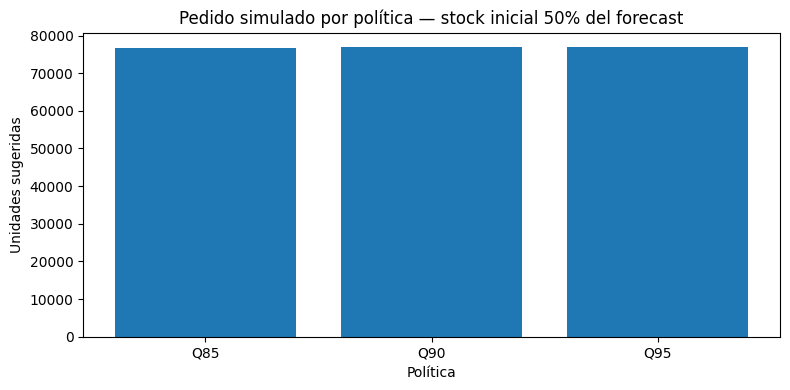

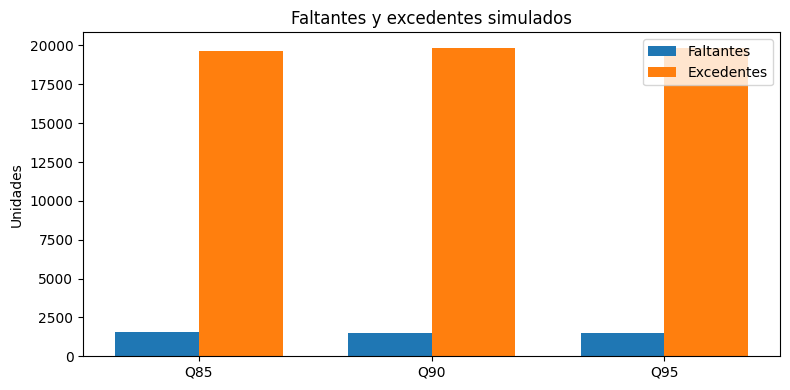

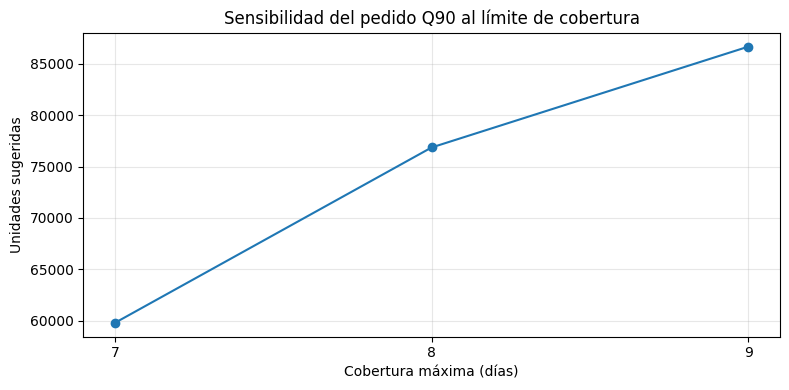

In [ ]:
mid = policy_results[policy_results["stock_inicial_pct_forecast"] == 0.5].copy()

plt.figure(figsize=(8, 4))
plt.bar(mid["politica"], mid["pedido_total"])
plt.title("Pedido simulado por política — stock inicial 50% del forecast")
plt.xlabel("Política")
plt.ylabel("Unidades sugeridas")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 4))
x = np.arange(len(mid))
plt.bar(x - 0.18, mid["faltantes_unidades"], width=0.36, label="Faltantes")
plt.bar(x + 0.18, mid["excedentes_unidades"], width=0.36, label="Excedentes")
plt.xticks(x, mid["politica"])
plt.title("Faltantes y excedentes simulados")
plt.ylabel("Unidades")
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 4))
plt.plot(
    coverage_results[coverage_results["stock_inicial_pct_forecast"] == 0.5]["cobertura_maxima_dias"],
    coverage_results[coverage_results["stock_inicial_pct_forecast"] == 0.5]["pedido_total"],
    marker="o"
)
plt.title("Sensibilidad del pedido Q90 al límite de cobertura")
plt.xlabel("Cobertura máxima (días)")
plt.ylabel("Unidades sugeridas")
plt.xticks([7, 8, 9])
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## 12. Exportación de resultados

Los archivos permiten documentar el desempeño del pronóstico, la comparación de políticas y la sensibilidad de cobertura.


In [ ]:
outputs = {
    "06_pronosticos_backtesting_semanal.csv": fold_forecasts,
    "06_metricas_pronostico_por_fold.csv": forecast_metrics_by_fold,
    "06_objetivos_politica_por_fold.csv": policy_targets,
    "06_simulacion_politicas_Q85_Q90_Q95.csv": policy_simulation,
    "06_resultados_politicas.csv": policy_results,
    "06_simulacion_cobertura_7_8_9_dias.csv": coverage_sim,
    "06_resultados_cobertura.csv": coverage_results,
    "06_resultados_Q90_por_tienda.csv": by_store,
    "06_resultados_Q90_por_producto.csv": by_product
}
for filename, df in outputs.items():
    df.to_csv(filename, index=False)
    print(f"Exportado: {filename} | filas: {len(df)}")


Exportado: 06_pronosticos_backtesting_semanal.csv | filas: 1440
Exportado: 06_metricas_pronostico_por_fold.csv | filas: 9
Exportado: 06_objetivos_politica_por_fold.csv | filas: 1280
Exportado: 06_simulacion_politicas_Q85_Q90_Q95.csv | filas: 11520
Exportado: 06_resultados_politicas.csv | filas: 9
Exportado: 06_simulacion_cobertura_7_8_9_dias.csv | filas: 11520
Exportado: 06_resultados_cobertura.csv | filas: 9
Exportado: 06_resultados_Q90_por_tienda.csv | filas: 20
Exportado: 06_resultados_Q90_por_producto.csv | filas: 8


## 13. Interpretación y limitaciones

### Qué sí permite concluir
- Qué tan preciso fue el pronóstico semanal en los bloques históricos evaluados.
- Cómo cambian los pedidos sugeridos al variar Q85/Q90/Q95.
- Cómo cambian faltantes y excedentes simulados bajo diferentes niveles hipotéticos de stock inicial.
- Qué productos y tiendas concentran los resultados de la simulación.

### Qué no permite concluir
- El fill rate histórico real de las tiendas.
- El ahorro financiero realmente alcanzado.
- La cantidad de ventas perdidas por quiebres.
- El efecto de lead time, pedidos en tránsito, frecuencia de despacho o capacidad de almacenamiento.
- Que las ventas registradas equivalgan siempre a demanda no censurada.

### Datos necesarios para un backtesting operacional definitivo
1. Inventario diario histórico por SKU–Tienda.
2. Pedidos emitidos, cantidades, fechas de despacho y recepción.
3. Lead time real y variabilidad por proveedor.
4. Quiebres de stock o disponibilidad diaria.
5. Merma, vencimiento, devoluciones y sustitución.
6. Costos completos de faltante y exceso.

**Recomendación:** presentar estos resultados como simulación contrafactual controlada y no como prueba de ahorro real. Para pasar a producción, se debe ejecutar un piloto con captura de inventario y recepción, y monitorear WAPE, fill rate, quiebres, días de inventario y merma.
